# Panel Regressions, Fixed Effects, and Difference-in-Differences

Much of empirical finance asks causal questions: *does* adopting a new technology raise a firm's profitability, *does* a regulation change bank lending, *does* a tax change alter CEO behavior? Last week's guest lecture on causal inference in finance made the core problem clear: we only ever observe correlations, and a correlation between $X$ and $Y$ can come from reverse causality or from an omitted third factor rather than from $X$ causing $Y$. This notebook studies one of the most widely used responses to the omitted-factor problem: **panel data** -- the same units (firms, banks, states) observed repeatedly over time -- combined with **fixed effects**, which compare each unit with *itself*.

We start with the simplest possible panel, just two periods, and show that the fixed effects idea in that setting *is* the **difference-in-differences** (DiD) design from the guest lecture. We then extend to many periods (firm and year fixed effects, the workhorse "two-way fixed effects" regression), and spend the second half of the notebook on what this approach does and does not buy you for causal inference. The regression machinery builds on `CAPM_BivariateRegression.ipynb` and `MultifactorModels_MultiVarRegression.ipynb`. In particular, everything here turns on Assumption 2 from `CAPM_BivariateRegression.ipynb`, $E(\epsilon_t \mid x_t) = 0$, which implies that the regressor is uncorrelated with the error term; the omitted-variable bias formula (which you also worked with in Homework 2) quantifies what happens when it fails. Serial correlation from `TimeSeries.ipynb` reappears when we discuss standard errors.

*Acknowledgment*: This notebook was produced with the assistance of AI. I remain responsible for the content and any errors.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Define panel data and the notation $y_{it}$, and explain why repeated observations on the same unit let us control for unobserved characteristics that never change.
2. Explain, using the omitted-variable bias formula, why a cross-sectional comparison of treated and untreated firms can be badly biased when an unobserved firm characteristic drives both treatment and outcomes.
3. Derive the two-period first-difference estimator, and show that with a treatment that switches on in the second period it is exactly the difference-in-differences estimator.
4. Estimate the same DiD effect four equivalent ways: a table of group means, a regression in first differences, a regression with $Treated$, $Post$ and $Treated \times Post$, and a regression with firm and year fixed effects.
5. State the parallel trends assumption in words and in symbols, and explain why it allows treated and control firms to differ in *levels*.
6. Explain the within (demeaning) transformation behind firm and year fixed effects, and estimate two-way fixed effects regressions in Python with `statsmodels`.
7. Estimate and interpret an event-study regression, and use its pre-treatment coefficients as a diagnostic for parallel trends.
8. Explain, and verify by simulation, five ways fixed effects estimates can mislead: time-varying confounders, treatment that responds to past outcomes, measurement error, staggered adoption with effects that change over time, and standard errors that ignore serial correlation.
9. (Optional, appendix) Show that the OLS slope on a 0/1 regressor is a difference in means, that fixed effects and first differences coincide when there are two periods, and (using matrix algebra) why the dummy-variable and demeaning versions of fixed effects give identical slopes.

## Instructions to Run

**Data:** No data files are needed. Every dataset in this notebook is *simulated* inside the notebook, for a reason explained in the motivating example below: in a simulation we know the true causal effect, so we can check which estimators recover it and which do not. (Where a notebook instead uses data that can't be redistributed here -- e.g. licensed WRDS data, or simply a larger extract -- the required file(s) will be posted on the course Canvas site under Data instead. Download those into your local `data/` folder before running.)

**If your data lives somewhere else:** Not applicable -- nothing is read from disk. If you adapt this code to a real panel, replace the calls to `simulate_panel(...)` with a `pd.read_csv(...)` of a long-format file with one row per firm-year (the path `../data/...` assumes this notebook lives in `notebooks/` and `data/` is a sibling folder).

**Package dependencies:** `numpy`, `pandas`, `matplotlib`, and `statsmodels` -- standard scientific-Python packages included in a typical Anaconda install. Otherwise: `pip install numpy pandas matplotlib statsmodels`. (Dedicated panel packages such as `linearmodels` exist, but everything here can be done with `statsmodels`, and doing the fixed effects transformation by hand once is instructive.)

**Viewing the HTML export in Canvas:** If the equations below show up as raw text (things like `$y_{it}$`) instead of typeset math, don't use Canvas's built-in file preview -- download the file and open it directly in your browser instead. Canvas's preview sandboxes uploaded HTML and blocks the script that typesets the math; opening the downloaded file locally has no such restriction.

## Motivating Example: Does AI Adoption Raise Profitability?

The guest lecture opened with the question *"Does using AI increase firm profitability?"*, and pointed out that a third factor -- **managerial quality** -- might drive both. Well-run firms are more likely to adopt new technology early, *and* well-run firms are more profitable for many other reasons. Managerial quality is very hard to measure, so we cannot simply add it to a regression as a control.

To see the problem (and later, the solution) clearly, we work with a simulated panel of 500 firms observed for 10 years. In each firm-year we record the firm's return on assets (ROA, in percent) and whether it has adopted AI. The simulation builds in the following features, which you can read off the function below:

- Each firm $i$ has a permanent **managerial quality** $\alpha_i$ (in ROA percentage points) that we, the econometricians, never get to see.
- Better-managed firms are more likely to be AI adopters. Adopters switch AI on in year 6 and keep it on.
- Each year $t$ has a common shock $\lambda_t$ that hits every firm (the business cycle).
- **The true causal effect of AI adoption on ROA is $\beta = 1$ percentage point.**

That last line is the luxury of simulation: with real data we would never know the right answer. Here we do, so we can grade each estimator.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

rng = np.random.default_rng(4414)

def simulate_panel(n_firms=500, n_years=10, beta=1.0, adopt_year=6, selection=1.0,
                   treated_trend=0.0, rho=0.0, sd_alpha=2.0, sd_eps=2.0):
    '''Simulate a balanced firm-year panel of ROA (in percent) and AI adoption.

    roa_it = 8 + alpha_i + lambda_t + beta * ai_it + treated_trend * treated_i * (t - adopt_year) + eps_it

    alpha_i       : permanent managerial quality, unobserved, N(0, sd_alpha^2)
    treated_i     : 1 if firm i adopts AI. P(treated) rises with alpha_i when selection > 0
    ai_it         : 1 if firm i is treated and t >= adopt_year (adoption is permanent)
    lambda_t      : common year shock, N(0, 1)
    treated_trend : extra ROA growth per year for treated firms (0 = parallel trends hold)
    eps_it        : firm-specific shock, AR(1) within firm with autocorrelation rho, sd sd_eps
    '''
    firm = np.repeat(np.arange(n_firms), n_years)
    year = np.tile(np.arange(1, n_years + 1), n_firms)

    alpha = rng.normal(0, sd_alpha, n_firms)
    prob_treat = 1 / (1 + np.exp(-selection * alpha / sd_alpha))     #logistic in alpha: 50% treated on average
    treated = (rng.random(n_firms) < prob_treat).astype(int)
    lam = rng.normal(0, 1, n_years)

    eps = np.empty((n_firms, n_years))
    eps[:, 0] = rng.normal(0, sd_eps, n_firms)
    for t in range(1, n_years):
        eps[:, t] = rho * eps[:, t - 1] + np.sqrt(1 - rho**2) * rng.normal(0, sd_eps, n_firms)

    df = pd.DataFrame({'firm': firm, 'year': year, 'alpha': alpha[firm], 'treated': treated[firm]})
    df['post'] = (df['year'] >= adopt_year).astype(int)
    df['ai'] = df['treated'] * df['post']
    df['roa'] = (8 + df['alpha'] + lam[year - 1] + beta * df['ai']
                 + treated_trend * df['treated'] * (df['year'] - adopt_year) + eps.ravel())
    return df

panel = simulate_panel()
panel.head(12)

,firm,year,alpha,treated,post,ai,roa
0,0,1,1.990603,0,0,0,8.809217
1,0,2,1.990603,0,0,0,8.829101
2,0,3,1.990603,0,0,0,7.956162
3,0,4,1.990603,0,0,0,10.630134
4,0,5,1.990603,0,0,0,9.776796
5,0,6,1.990603,0,1,0,8.541896
6,0,7,1.990603,0,1,0,7.358431
7,0,8,1.990603,0,1,0,9.075794
8,0,9,1.990603,0,1,0,14.975206
9,0,10,1.990603,0,1,0,12.747466


The data are in **long format**: one row per firm-year, with a firm identifier and a year identifier. This is the standard layout for panel data, and the layout every panel regression routine expects. (The `alpha` column is there so that *we* can check things; a real researcher would not have it.)

A natural first analysis is a cross-sectional comparison: in the last year of data, how much more profitable are AI adopters than non-adopters? Equivalently, regress ROA on the AI indicator using year-10 data only.

In [2]:
#Cross-sectional comparison in the final year: regress ROA on the AI dummy
last = panel[panel['year'] == panel['year'].max()]
xsec = smf.ols('roa ~ ai', data=last).fit(cov_type='HC1')
print(f"Average ROA, AI adopters:     {last.loc[last['ai'] == 1, 'roa'].mean():.2f}%")
print(f"Average ROA, non-adopters:    {last.loc[last['ai'] == 0, 'roa'].mean():.2f}%")
print(f"Cross-sectional estimate:     {xsec.params['ai']:.2f}  (t = {xsec.tvalues['ai']:.1f})")
print(f"True causal effect:           1.00")
print(f"\nAverage managerial quality, adopters minus non-adopters: "
      f"{last.loc[last['ai'] == 1, 'alpha'].mean() - last.loc[last['ai'] == 0, 'alpha'].mean():.2f}")

Average ROA, AI adopters:     9.77%
Average ROA, non-adopters:    7.05%
Cross-sectional estimate:     2.72  (t = 10.9)
True causal effect:           1.00

Average managerial quality, adopters minus non-adopters: 1.60


The regression reports a large and highly significant "effect" of AI -- but it is far bigger than the true effect of 1 percentage point. The last line shows why: adopters have much higher managerial quality on average, and the cross-sectional comparison attributes all of the resulting profitability gap to AI.

This is a failure of Assumption 2 from `CAPM_BivariateRegression.ipynb`: managerial quality sits in the error term, and it is correlated with the regressor, so $\text{Cov}(\epsilon, x) \neq 0$. The resulting **omitted-variable bias** (the same formula as in Homework 2) has a simple form. If the true model is $y = a + b\,x + c\,f + u$ but we regress $y$ on $x$ alone, the slope we estimate converges to

$$b + c \times \frac{\text{Cov}(x, f)}{\text{Var}(x)}.$$

Here $x$ is the AI dummy, the omitted $f$ is managerial quality $\alpha_i$, and $c = 1$ (one point of managerial quality is one point of ROA). Because $x$ is a 0/1 variable, $\text{Cov}(x,f)/\text{Var}(x)$ is just the difference in average $f$ between adopters and non-adopters (see the appendix), which is the number printed on the last line. So the bias is roughly that gap, and that is about what we see.

Adding observable controls (size, industry, age) might shrink the bias, but it cannot remove the part due to an *unobservable* like managerial quality. The rest of this notebook is about a different strategy: use the fact that we observe each firm **more than once**.

## Panel Data and Unobserved Heterogeneity

A **panel** (or *longitudinal*) dataset follows the same $N$ units over $T$ time periods. We write $y_{it}$ for the outcome of unit $i$ in period $t$, with $i = 1, \ldots, N$ and $t = 1, \ldots, T$. In finance the units are typically firms, funds, banks, or countries; the panel in this notebook has $N = 500$ firms and $T = 10$ years. (If every unit is observed in every period, the panel is **balanced**. Real panels are often unbalanced -- firms are born, delisted, and merged -- but that changes the bookkeeping more than the ideas.)

Our model for ROA is

$$y_{it} = \alpha_i + \lambda_t + \beta D_{it} + \varepsilon_{it}, \tag{1}$$

where $D_{it}$ is the treatment (AI) indicator, $\beta$ is the causal effect we want, and

- $\alpha_i$ is a **unit (firm) fixed effect**: everything about firm $i$ that affects ROA and does not change over time -- managerial quality here, but also location, business model, corporate culture, and so on. We do not need to observe or even name these things.
- $\lambda_t$ is a **time (year) fixed effect**: everything that shifts ROA for *all* firms in year $t$ -- recessions, interest rates, the arrival of a new technology wave.
- $\varepsilon_{it}$ is everything else: shocks specific to firm $i$ in year $t$.

(The constant 8 in the simulation is absorbed into the $\alpha_i$'s.) Notice the word "fixed" means *fixed over time* for $\alpha_i$ (and fixed across firms for $\lambda_t$); it does not mean the $\alpha_i$'s are the same for different firms. They are not, and that is the whole problem.

The cross-sectional regression above ignored $\alpha_i$, leaving it in the error term. Because $\alpha_i$ is correlated with $D_{it}$, the estimate was biased. The question is whether repeated observations let us get rid of $\alpha_i$ without ever measuring it.

## The Simplest Panel: Two Periods

Start with just two periods, $t = 1$ ("before") and $t = 2$ ("after"). Write equation (1) for each period:

$$y_{i2} = \alpha_i + \lambda_2 + \beta D_{i2} + \varepsilon_{i2}$$
$$y_{i1} = \alpha_i + \lambda_1 + \beta D_{i1} + \varepsilon_{i1}$$

Subtract the second line from the first. The firm effect $\alpha_i$ appears in both lines with the same coefficient, so it **cancels**:

$$y_{i2} - y_{i1} = (\alpha_i - \alpha_i) + (\lambda_2 - \lambda_1) + \beta (D_{i2} - D_{i1}) + (\varepsilon_{i2} - \varepsilon_{i1})$$

$$\Delta y_i = \Delta\lambda + \beta\, \Delta D_i + \Delta\varepsilon_i, \tag{2}$$

where $\Delta$ denotes the change from period 1 to period 2. Equation (2) is a cross-sectional regression -- one observation per firm -- of the *change* in ROA on the *change* in treatment, with an intercept $\Delta\lambda$. This is the **first-difference (FD) estimator**. The unobserved managerial quality has disappeared, without our ever measuring it: a firm's managerial quality affects its *level* of ROA, but not its *change* in ROA, because it is the same in both years.

In plain words: instead of comparing firms with *other* firms, which differ in a thousand unobserved ways, we compare each firm with *itself* one period earlier.

### From first differences to difference-in-differences

Now add the structure of a typical policy or adoption event: **nobody is treated in period 1**, and some firms (the treated group) are treated in period 2. Then $D_{i1} = 0$ for every firm and $D_{i2} = Treated_i$, so $\Delta D_i = Treated_i$, and equation (2) becomes

$$\Delta y_i = \Delta\lambda + \beta\, Treated_i + \Delta\varepsilon_i. \tag{3}$$

This is a regression of the change in ROA on a 0/1 dummy. The OLS slope on a 0/1 regressor is always the difference between the average outcome in the "1" group and the average outcome in the "0" group (shown in the appendix). So the estimate of $\beta$ is

$$\hat\beta = \overline{\Delta y}_{\text{treated}} - \overline{\Delta y}_{\text{control}} = \big(\bar y_{T,2} - \bar y_{T,1}\big) - \big(\bar y_{C,2} - \bar y_{C,1}\big),$$

the *difference* (treated minus control) of the *differences* (after minus before). That is precisely the **difference-in-differences** estimator from the guest lecture's Colorado / Virginia salary-transparency example: Colorado salaries rose $\$8$k, Virginia's rose $\$5$k, so the estimated effect of the law is $\$8\text{k} - \$5\text{k} = \$3\text{k}$. The control group's change (Virginia's $\$5$k) stands in for what *would* have happened to the treated group without treatment -- its counterfactual.

So **difference-in-differences is a two-period panel regression with unit fixed effects** (differencing is how the fixed effect is removed). Let us verify this on simulated data.

In [3]:
#Two-period version of the AI panel: period 1 = before, period 2 = after (adopters switch AI on in period 2)
two = simulate_panel(n_years=2, adopt_year=2)

#The classic 2x2 table of group means
means = two.pivot_table(index='treated', columns='year', values='roa').rename(
    index={0: 'Control (non-adopters)', 1: 'Treated (adopters)'}, columns={1: 'Before', 2: 'After'})
means['Change'] = means['After'] - means['Before']
print(means.round(2))
did_table = means['Change'].iloc[1] - means['Change'].iloc[0]
print(f"\nDifference-in-differences: {means['Change'].iloc[1]:.2f} - ({means['Change'].iloc[0]:.2f}) = {did_table:.2f}")
print(f"Naive 'after' comparison:  {means['After'].iloc[1] - means['After'].iloc[0]:.2f}")
print(f"True causal effect:        1.00")

year                    Before  After  Change
treated                                      
Control (non-adopters)    8.01   5.64   -2.36
Treated (adopters)        9.81   8.50   -1.31

Difference-in-differences: -1.31 - (-2.36) = 1.05
Naive 'after' comparison:  2.85
True causal effect:        1.00


The naive comparison in the "after" period is badly biased, just as in the motivating example: treated firms were *already* more profitable before anyone adopted AI (compare the "Before" column), because they have better managers. The DiD estimate nets out that pre-existing gap and lands close to the true value of 1. (It is not exactly 1 because of the random shocks $\varepsilon_{it}$ -- it is an estimate.)

Next, the same number three more ways:

1. **First differences**, equation (3): regress each firm's change in ROA on $Treated_i$.
2. **The DiD regression from the guest lecture**: using both periods (two rows per firm), regress
$$y_{it} = a + b\, Treated_i + c\, Post_t + \delta\, (Treated_i \times Post_t) + \varepsilon_{it}.$$
Here $a$ is the control group's average before, $b$ is the treated-control gap before, $c$ is the control group's change, and $\delta$ -- the coefficient on the interaction -- is the *extra* change for the treated group: the DiD.
3. **Firm and year fixed effects**: regress $y_{it}$ on $D_{it}$ plus a dummy variable for every firm and every year, i.e. estimate equation (1) directly. In `statsmodels` formulas, `C(firm)` creates one dummy per firm.

In [4]:
#(1) First differences: one row per firm
wide = two.pivot(index='firm', columns='year', values='roa')
fd = pd.DataFrame({'d_roa': wide[2] - wide[1], 'treated': two.groupby('firm')['treated'].first()})
fd_res = smf.ols('d_roa ~ treated', data=fd).fit()

#(2) Treated, Post, and their interaction
did_res = smf.ols('roa ~ treated + post + treated:post', data=two).fit()

#(3) Firm and year fixed effects (a dummy for every firm and every year)
fe_res = smf.ols('roa ~ ai + C(firm) + C(year)', data=two).fit()

print(f"2x2 table of means:              {did_table:.4f}")
print(f"First differences:               {fd_res.params['treated']:.4f}")
print(f"Treated x Post interaction:      {did_res.params['treated:post']:.4f}")
print(f"Firm + year fixed effects:       {fe_res.params['ai']:.4f}")

2x2 table of means:              1.0482
First differences:               1.0482
Treated x Post interaction:      1.0482
Firm + year fixed effects:       1.0482


All four agree to every decimal place shown. They are not four different estimators that happen to be close; in a balanced two-period panel they are algebraically the *same* estimator (see the appendix for the fixed effects / first differences equivalence).

That equivalence is the bridge between the two ways people talk about this design. Applied researchers often describe it as "difference-in-differences" with a $Treated \times Post$ interaction; econometrics texts describe it as "a panel regression with unit fixed effects." The second description generalizes naturally to many periods, many treatment dates, and continuous treatments, which is why the fixed effects regression is the workhorse in empirical finance.

### Does DiD really fix the bias? A simulation

A single simulated sample could be lucky. Below we draw 1,000 independent two-period panels from the same model and compute both the naive after-period comparison and the DiD estimate in each one. If DiD is unbiased, its estimates should be centered on the true effect of 1.

      naive    did
mean  2.654  0.999
std   0.235  0.249


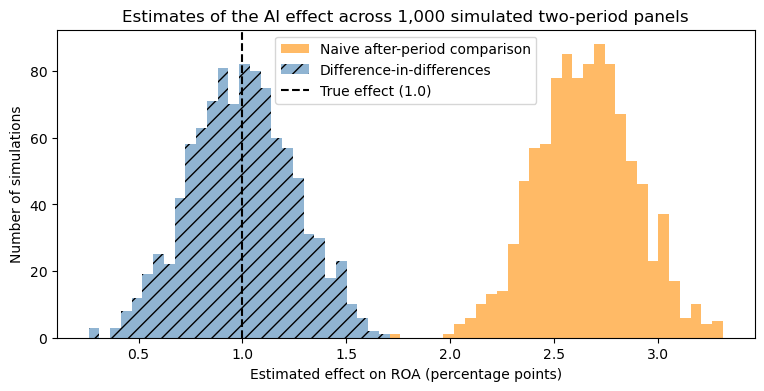

In [5]:
#Monte Carlo: sampling distributions of the naive cross-sectional estimate and the DiD estimate
def did_2x2(df):
    '''DiD from a two-period panel: (treated after - before) minus (control after - before).'''
    m = df.groupby(['treated', 'year'])['roa'].mean()
    return (m[1, 2] - m[1, 1]) - (m[0, 2] - m[0, 1])

def naive_after(df):
    m = df[df['year'] == 2].groupby('treated')['roa'].mean()
    return m[1] - m[0]

n_sims = 1000
mc = pd.DataFrame([(naive_after(s), did_2x2(s)) for s in
                   (simulate_panel(n_years=2, adopt_year=2) for _ in range(n_sims))],
                  columns=['naive', 'did'])
print(mc.agg(['mean', 'std']).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(mc.min().min(), mc.max().max(), 60)
ax.hist(mc['naive'], bins=bins, alpha=0.6, color='darkorange', label='Naive after-period comparison')
ax.hist(mc['did'], bins=bins, alpha=0.6, color='steelblue', hatch='//', label='Difference-in-differences')
ax.axvline(1.0, color='black', linestyle='--', linewidth=1.5, label='True effect (1.0)')
ax.set_title(f"Estimates of the AI effect across {n_sims:,} simulated two-period panels")
ax.set_xlabel("Estimated effect on ROA (percentage points)")
ax.set_ylabel("Number of simulations")
ax.legend()
plt.show()

The naive estimator is consistently wrong: its distribution is centered far to the right of the truth, and a larger sample would not help -- it would just make it more precisely wrong. The DiD estimates are centered on the true effect.

DiD is not free, though. Its distribution is slightly wider than the naive one here, because a *change* contains two years of shocks, $\varepsilon_{i2} - \varepsilon_{i1}$, whereas the after-period level contains one (plus the managerial-quality differences, which add their own noise). Fixed effects designs often trade bias for variance in this way.

### The key assumption: parallel trends

Why does DiD work in this simulation? Go back to equation (3). OLS gives an unbiased estimate of $\beta$ if the error $\Delta\varepsilon_i$ is unrelated to treatment -- that is, if on average the treated and control groups would have had the same change in the error:

$$E\big[\varepsilon_{i2} - \varepsilon_{i1} \mid Treated_i = 1\big] = E\big[\varepsilon_{i2} - \varepsilon_{i1} \mid Treated_i = 0\big].$$

In words: **in the absence of treatment, ROA would have changed by the same amount, on average, for treated and control firms.** This is the **parallel trends** assumption from the guest lecture. Two features deserve emphasis:

- It is an assumption about the *counterfactual*, the path the treated firms would have followed without AI. That path is never observed after treatment, so the assumption can never be fully tested. (We will see a partial check below.)
- It does **not** require treated and control firms to be similar in *levels*. Adopters can be far more profitable than non-adopters -- because of managerial quality, or anything else time-invariant -- and DiD still works, as long as the gap would have stayed *constant*. Compared with the naive comparison, which needs the groups to be identical on average in everything except treatment, this is a much weaker requirement. That is the main selling point of fixed effects.

The plot below shows average ROA by group over the full 10-year panel. The dashed line is the treated group's counterfactual path implied by parallel trends: the treated group's pre-adoption gap over the control group, carried forward.

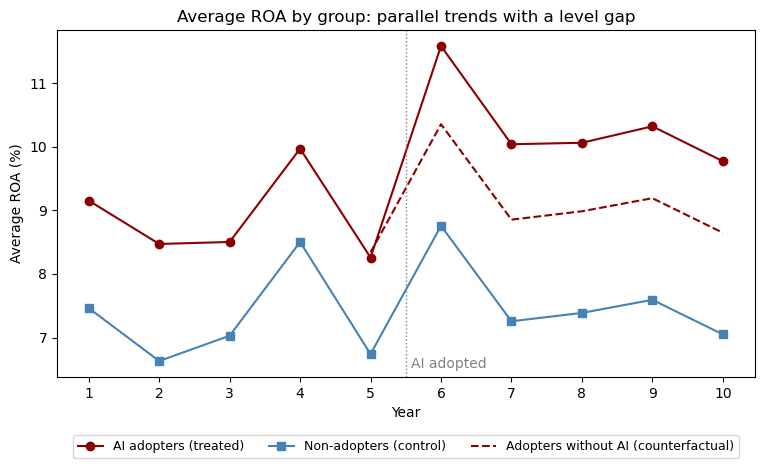

In [6]:
#Average ROA by group and year, with the parallel-trends counterfactual for the treated group
grp = panel.groupby(['year', 'treated'])['roa'].mean().unstack()
pre_gap = (grp[1] - grp[0])[grp.index < 6].mean()
counterfactual = grp[0] + pre_gap

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(grp.index, grp[1], color='darkred', marker='o', label='AI adopters (treated)')
ax.plot(grp.index, grp[0], color='steelblue', marker='s', label='Non-adopters (control)')
ax.plot(grp.index[grp.index >= 5], counterfactual[grp.index >= 5], color='darkred', linestyle='--',
        label='Adopters without AI (counterfactual)')
ax.axvline(5.5, color='gray', linestyle=':', linewidth=1)
ax.annotate('AI adopted', (5.5, ax.get_ylim()[0]), xytext=(4, 6), textcoords='offset points', color='gray')
ax.set_title("Average ROA by group: parallel trends with a level gap")
ax.set_xlabel("Year")
ax.set_ylabel("Average ROA (%)")
ax.set_xticks(grp.index)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
plt.show()

Both groups move up and down together with the common year shocks $\lambda_t$, and the adopters sit well above the non-adopters throughout -- that level gap is managerial quality. After adoption in year 6, the treated line separates from its dashed counterfactual by roughly the true effect of 1 percentage point. Before adoption, the two solid lines move in parallel, apart from random noise; that is what the assumption looks like when it holds.

## Many Periods: Firm and Year Fixed Effects

With more than two periods, differencing is no longer the only way to remove $\alpha_i$. The more common approach is the **within transformation**: subtract each firm's own time-series average from each of its observations.

Average equation (1) over the $T$ years for firm $i$. Writing $\bar y_i = \frac{1}{T}\sum_{t} y_{it}$ (and similarly for $\bar D_i$, $\bar\lambda$, $\bar\varepsilon_i$), and noting that the average of the constant $\alpha_i$ is just $\alpha_i$:

$$\bar y_i = \alpha_i + \bar\lambda + \beta \bar D_i + \bar\varepsilon_i.$$

Subtracting this from equation (1), $\alpha_i$ again cancels:

$$y_{it} - \bar y_i = (\lambda_t - \bar\lambda) + \beta (D_{it} - \bar D_i) + (\varepsilon_{it} - \bar\varepsilon_i).$$

The year effects are still there; we can remove them by also subtracting each year's cross-sectional average (and, in a balanced panel, adding back the overall average so that nothing is subtracted twice). Writing $\tilde y_{it} = y_{it} - \bar y_i - \bar y_t + \bar y$ for this **two-way demeaned** variable (where $\bar y_t$ is the year-$t$ average across firms and $\bar y$ is the grand average), and similarly for $\tilde D_{it}$ and $\tilde\varepsilon_{it}$, the model becomes

$$\tilde y_{it} = \beta \tilde D_{it} + \tilde\varepsilon_{it},$$

a simple regression with no intercept, which we can estimate by OLS. This is the **two-way fixed effects (TWFE)** estimator. Equivalently -- and this is how most software reports it -- we can regress $y_{it}$ on $D_{it}$ plus a full set of firm dummies and year dummies, the **least squares dummy variable (LSDV)** approach. The two give the identical $\hat\beta$ (see the appendix for why). Demeaning is much faster when there are thousands of firms, because it avoids estimating thousands of dummy coefficients.

In plain words, the within transformation asks: *in years when this firm's AI status is above its own average, is its ROA above its own average, by more than the typical firm's ROA is above average that year?*

The code below estimates four regressions on the 10-year panel: pooled OLS (no fixed effects), firm fixed effects only, two-way fixed effects via dummies, and two-way fixed effects via demeaning by hand.

In [7]:
def twoway_demean(df, col):
    '''Two-way within transformation for a balanced panel: y_it - ybar_i - ybar_t + ybar.'''
    return (df[col] - df.groupby('firm')[col].transform('mean')
            - df.groupby('year')[col].transform('mean') + df[col].mean())

def fe_slope(df, y='roa', x='ai'):
    '''Two-way fixed effects slope estimate via demeaning (balanced panel, one regressor).'''
    y_dm, x_dm = twoway_demean(df, y), twoway_demean(df, x)
    return (x_dm * y_dm).sum() / (x_dm**2).sum()

pooled  = smf.ols('roa ~ ai', data=panel).fit()
firm_fe = smf.ols('roa ~ ai + C(firm)', data=panel).fit()
twfe    = smf.ols('roa ~ ai + C(firm) + C(year)', data=panel).fit()

print(f"Pooled OLS (no fixed effects):      {pooled.params['ai']:.3f}")
print(f"Firm fixed effects only:            {firm_fe.params['ai']:.3f}")
print(f"Firm + year FE (dummies):           {twfe.params['ai']:.3f}")
print(f"Firm + year FE (demeaned by hand):  {fe_slope(panel):.3f}")
print(f"True causal effect:                 1.000")
print(f"\nNumber of estimated coefficients in the dummy-variable regression: {len(twfe.params)}")

Pooled OLS (no fixed effects):      2.490
Firm fixed effects only:            1.485
Firm + year FE (dummies):           1.149
Firm + year FE (demeaned by hand):  1.149
True causal effect:                 1.000

Number of estimated coefficients in the dummy-variable regression: 510


A few things to notice:

- **Pooled OLS** treats all 5,000 firm-years as unrelated observations and is biased upward by managerial quality, just like the cross-section.
- **Firm fixed effects alone** remove managerial quality, but they compare each adopter's post-adoption years with its own pre-adoption years, so any common shock that happens to differ between the before and after periods gets attributed to AI. (In the simulation the year shocks $\lambda_t$ are random, so this bias can go either way from one sample to the next.) The non-adopters are what allow us to separate "AI" from "what happened to everyone after year 5" -- that is the job of the year fixed effects, and it is exactly the role the control group plays in DiD.
- **Two-way fixed effects** are close to the truth, and the dummy-variable and demeaned versions agree exactly, even though one estimated over 500 coefficients and the other estimated one.

Because there is a single adoption date here, the TWFE estimate is just a many-period DiD: the average post-minus-pre change for adopters minus the average post-minus-pre change for non-adopters.

### What identifies $\beta$: within-firm variation

The within transformation throws away all **between-firm** variation -- differences in the average level of $y$ and $D$ across firms -- and uses only **within-firm** variation over time. This has three consequences worth keeping in mind:

1. Only firms whose treatment status *changes* during the sample contribute to $\hat\beta$. A firm that is always or never treated still helps estimate the year effects, but it says nothing directly about the effect of switching.
2. Anything that does not vary over time within a firm -- its industry, founding year, headquarters state, the CEO's gender if the CEO never changes -- is perfectly collinear with the firm dummies, so its coefficient **cannot be estimated** with firm fixed effects. It is absorbed into $\alpha_i$.
3. When a regressor barely moves within firms, the fixed effects estimate can be very imprecise, and (as we will see) very sensitive to measurement error.

### Standard errors: cluster by firm

The regressions above report conventional OLS standard errors, which assume that the errors $\varepsilon_{it}$ are independent across all firm-years. In panels that is rarely plausible: a firm's shock this year is usually correlated with its shock last year (recall persistence from `TimeSeries.ipynb`). The standard fix is **clustered standard errors**, which allow arbitrary correlation among the errors of the same firm (the *cluster*) while assuming independence across firms. We come back to why this matters, with a simulation, in the next section; from here on we cluster by firm. In `statsmodels`, add `cov_type='cluster'` and pass the firm identifier:

In [8]:
twfe_cl = smf.ols('roa ~ ai + C(firm) + C(year)', data=panel).fit(cov_type='cluster',
                                                                  cov_kwds={'groups': panel['firm']})
print(f"TWFE estimate: {twfe_cl.params['ai']:.3f}")
print(f"Conventional SE: {twfe.bse['ai']:.3f}    Firm-clustered SE: {twfe_cl.bse['ai']:.3f}")
ci = twfe_cl.conf_int().loc['ai']
print(f"95% CI (clustered): [{ci[0]:.3f}, {ci[1]:.3f}]")

TWFE estimate: 1.149
Conventional SE: 0.114    Firm-clustered SE: 0.119
95% CI (clustered): [0.916, 1.382]


In this first simulation the shocks are independent over time ($\rho = 0$ in `simulate_panel`), so the two standard errors are similar. With persistent shocks they are not, as we will see.

### Event studies: looking at the effect year by year

The TWFE regression produces one number. A more informative version, called an **event study**, replaces the single treatment dummy with a separate dummy for each year relative to adoption, for treated firms:

$$y_{it} = \alpha_i + \lambda_t + \sum_{k \neq -1} \delta_k \, \mathbb{1}\{Treated_i = 1 \text{ and } t - 6 = k\} + \varepsilon_{it}.$$

Here $k = t - 6$ is "event time": $k = 0$ is the adoption year, $k = -1$ the year just before, and so on. Each $\delta_k$ is a DiD comparing treated and control firms in event year $k$ relative to event year $-1$, which is left out as the baseline (some year has to be, or the dummies would be collinear with the firm effects).

The event study gives two things at once:

- The **post-treatment** coefficients ($k \geq 0$) show how the effect evolves: immediate or gradual, permanent or fading.
- The **pre-treatment** coefficients ($k < -1$) are a **placebo test**: treatment has not happened yet, so if parallel trends holds they should be close to zero. A pattern in the pre-period coefficients is a red flag. This is the "partial check" on parallel trends mentioned earlier: it checks whether trends were parallel *before* treatment, which is suggestive but not proof that they would have stayed parallel afterwards.

   k  coef    lo    hi
0 -5  0.17 -0.33  0.68
1 -4  0.32 -0.19  0.84
2 -3 -0.04 -0.53  0.45
3 -2 -0.05 -0.59  0.49
4 -1  0.00  0.00  0.00
5  0  1.31  0.78  1.84
6  1  1.27  0.74  1.79
7  2  1.16  0.64  1.68
8  3  1.21  0.68  1.74
9  4  1.21  0.73  1.68


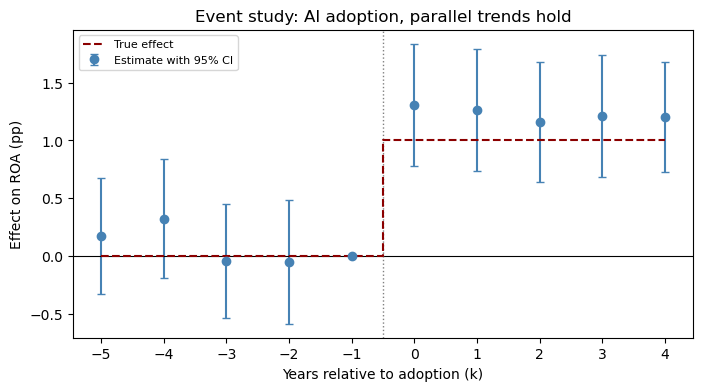

In [9]:
def event_study(df, adopt_year=6, base=-1):
    '''Event-study regression with firm and year FE, firm-clustered SEs. Returns a DataFrame of
    coefficients and 95% CIs by event time k = year - adopt_year (baseline k = base is zero by construction).'''
    df = df.copy()
    ks = sorted(set(df['year'] - adopt_year) - {base})
    names = []
    for k in ks:
        name = f"ev_m{-k}" if k < 0 else f"ev_p{k}"
        df[name] = ((df['treated'] == 1) & (df['year'] - adopt_year == k)).astype(int)
        names.append(name)
    res = smf.ols('roa ~ ' + ' + '.join(names) + ' + C(firm) + C(year)', data=df).fit(
        cov_type='cluster', cov_kwds={'groups': df['firm']})
    out = pd.DataFrame({'k': ks, 'coef': res.params[names].values,
                        'lo': res.conf_int().loc[names, 0].values, 'hi': res.conf_int().loc[names, 1].values})
    base_row = pd.DataFrame({'k': [base], 'coef': [0.0], 'lo': [0.0], 'hi': [0.0]})
    return pd.concat([out, base_row]).sort_values('k').reset_index(drop=True)

def plot_event_study(es, ax, title, true_effect=None, legend_loc='upper left'):
    ax.errorbar(es['k'], es['coef'], yerr=[es['coef'] - es['lo'], es['hi'] - es['coef']],
                fmt='o', color='steelblue', ecolor='steelblue', capsize=3, label='Estimate with 95% CI')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(-0.5, color='gray', linestyle=':', linewidth=1)
    if true_effect is not None:
        ax.plot(es['k'], np.where(es['k'] >= 0, true_effect, 0), color='darkred', linestyle='--',
                drawstyle='steps-mid', label='True effect')
    ax.set_title(title)
    ax.set_xlabel("Years relative to adoption (k)")
    ax.set_ylabel("Effect on ROA (pp)")
    ax.set_xticks(es['k'])
    ax.legend(loc=legend_loc, fontsize=8)

es_clean = event_study(panel)
print(es_clean.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
plot_event_study(es_clean, ax, "Event study: AI adoption, parallel trends hold", true_effect=1.0)
plt.show()

The pre-adoption coefficients are scattered around zero with confidence intervals that comfortably include zero, and the post-adoption coefficients sit around the true effect of 1. This is what a "clean" event study looks like. Published papers using DiD in finance almost always include a figure like this one.

## What Fixed Effects Buy You -- and What They Don't

**The benefit.** Firm fixed effects remove *every* time-invariant firm characteristic from the error term -- observed or unobserved, measured well or badly, even ones the researcher never thought of. Year fixed effects do the same for every shock common to all firms in a given year. That is a lot of potential omitted-variable bias eliminated at once, without having to collect a single extra control variable. It is why referees in finance routinely ask "did you include firm fixed effects?"

**The catch.** Fixed effects do *not* make a regression causal by themselves. Removing $\alpha_i$ and $\lambda_t$ means that the remaining requirement is about the *within-firm, over-time* variation: the change in treatment must be unrelated to changes in everything else that affects the outcome. More precisely, TWFE estimates $\beta$ without bias if

$$E\big[\varepsilon_{it} \mid D_{i1}, D_{i2}, \ldots, D_{iT}, \alpha_i\big] = 0,$$

a condition called **strict exogeneity**: a firm's treatment in *any* year is unrelated to its idiosyncratic shocks in *every* year -- past, present, and future. With one adoption date this is the parallel trends assumption again.

Each subsection below shows a way this goes wrong -- or, in the last two, a way the results mislead even when it holds (an effect that is not one constant number, and standard errors that are too small) -- using the same simulation approach so that we always know the truth. The guest lecture's two threats to causal inference -- omitted variables and reverse causality -- reappear in the first two.

### Drawback 1: Time-varying confounders (non-parallel trends)

Fixed effects remove omitted variables that are *constant*. An omitted variable that *changes over time* differently for treated and control firms is untouched. Suppose, for instance, that the firms that adopt AI are the ones whose **growth opportunities are improving** (the guest lecture listed growth opportunities as a classic unobservable). Their ROA would have been trending up relative to non-adopters even without AI. DiD then attributes that trend to AI.

In the simulation, set `treated_trend=0.4`: adopters' ROA rises by an extra 0.4 percentage points per year relative to non-adopters, over the whole sample, for reasons that have nothing to do with AI. The true AI effect is still 1.

TWFE estimate with differential trends: 3.05 (clustered SE 0.12); true effect 1.00


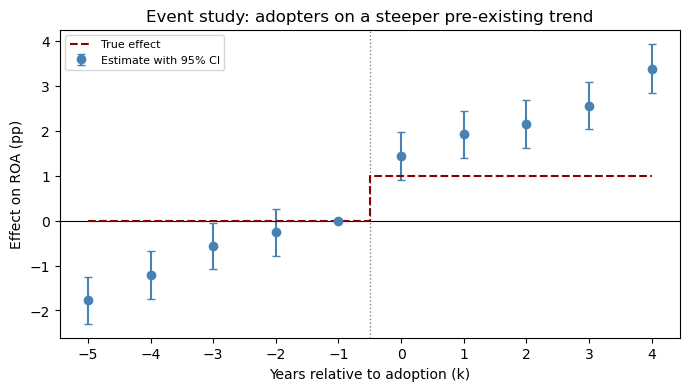

In [10]:
#Treated firms are on a steeper trend (0.4 pp per year) even without AI; true effect is still 1
panel_trend = simulate_panel(treated_trend=0.4)
twfe_trend = smf.ols('roa ~ ai + C(firm) + C(year)', data=panel_trend).fit(
    cov_type='cluster', cov_kwds={'groups': panel_trend['firm']})
print(f"TWFE estimate with differential trends: {twfe_trend.params['ai']:.2f} "
      f"(clustered SE {twfe_trend.bse['ai']:.2f}); true effect 1.00")

es_trend = event_study(panel_trend)
fig, ax = plt.subplots(figsize=(8, 4))
plot_event_study(es_trend, ax, "Event study: adopters on a steeper pre-existing trend", true_effect=1.0)
plt.show()

The TWFE estimate is now far too large, and its standard error gives no hint of a problem -- a small standard error just means the *biased* number is precisely estimated. The event study, however, gives the game away: the pre-adoption coefficients march steadily upward *before* anyone adopted AI. Treated firms were already pulling away from the control group, so the post-adoption gap cannot be credited to AI.

Common responses in practice include choosing a control group that looks more similar in pre-period trends (matching on pre-treatment characteristics), adding controls for observable time-varying factors, or allowing for group-specific trends. Each helps only if the analyst can correctly guess the form of the violation. The most convincing remedy is a better source of variation: a treatment whose *timing* is driven by something plausibly unrelated to firms' prospects, such as a law passed for unrelated reasons -- the "quasi-natural experiments" from the guest lecture.

### Drawback 2: Treatment that responds to past outcomes

The guest lecture's first threat was **reverse causality**: maybe $Y$ causes $X$. Panel data partly address it by timing (treatment happens at a known date), but fixed effects create a subtle version of their own. Suppose firms adopt AI *in response to a bad year*: management, unhappy with a temporary profitability slump, invests in a new technology. Temporary shocks fade, so ROA would have bounced back on its own. A before/after comparison then credits AI with a recovery that was going to happen anyway. Labor economists call this pattern the **Ashenfelter dip**, after the finding that workers who enter job-training programs tend to have had unusually low earnings just before entering.

To simulate this, the code below lets firms whose firm-specific shock in year 5 is in the bottom 30% adopt AI in year 6. Managerial quality plays no role in adoption this time, and **the true AI effect is zero**.

Two-period DiD, years 5 vs 6:       3.07   (true effect 0)
TWFE estimate, all 10 years:        0.45   (true effect 0)


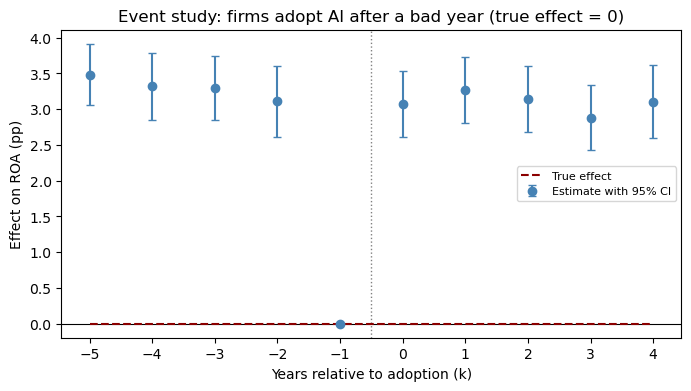

In [11]:
def simulate_dip(n_firms=500, n_years=10, adopt_year=6, share=0.3, sd_alpha=2.0, sd_eps=2.0):
    '''Firms adopt AI in adopt_year if their year (adopt_year - 1) shock is in the bottom `share`.
    The true effect of AI is ZERO. Shocks are independent over time.'''
    firm = np.repeat(np.arange(n_firms), n_years)
    year = np.tile(np.arange(1, n_years + 1), n_firms)
    eps = rng.normal(0, sd_eps, (n_firms, n_years))
    treated = (eps[:, adopt_year - 2] < np.quantile(eps[:, adopt_year - 2], share)).astype(int)
    df = pd.DataFrame({'firm': firm, 'year': year, 'treated': treated[firm]})
    df['post'] = (df['year'] >= adopt_year).astype(int)
    df['ai'] = df['treated'] * df['post']
    df['roa'] = 8 + rng.normal(0, sd_alpha, n_firms)[firm] + rng.normal(0, 1, n_years)[year - 1] + eps.ravel()
    return df

panel_dip = simulate_dip()

#A two-period DiD using the year just before (5) and just after (6) adoption
two_dip = panel_dip[panel_dip['year'].isin([5, 6])].copy()
two_dip['year'] = two_dip['year'] - 4          #relabel as periods 1 and 2 for did_2x2()
print(f"Two-period DiD, years 5 vs 6:       {did_2x2(two_dip):.2f}   (true effect 0)")
print(f"TWFE estimate, all 10 years:        {fe_slope(panel_dip):.2f}   (true effect 0)")

es_dip = event_study(panel_dip)
fig, ax = plt.subplots(figsize=(8, 4))
plot_event_study(es_dip, ax, "Event study: firms adopt AI after a bad year (true effect = 0)", true_effect=0.0,
                 legend_loc='center right')
plt.show()

Both estimators find a positive "effect" of a treatment that does nothing. The two-period DiD that compares the slump year with the year after is the worst, because it measures almost pure bounce-back. The 10-year TWFE estimate is smaller but still clearly positive: the slump year is one of the adopters' five "before" years, and it drags down their pre-adoption average.

Notice the event study's shape. Every coefficient is measured relative to $k = -1$, the slump year itself. Because the slump is the baseline, *all* the other coefficients -- before and after adoption -- sit well above zero, at roughly the same height. The flat post-period looks like a permanent effect of AI, but the equally high pre-period coefficients say that year $-1$ was the unusual one. Choosing a different baseline (say $k = -2$) would show the same thing as a dip at $k = -1$.

Two lessons. First, *why* units get treated when they do matters as much as *whether* they differ in levels; strict exogeneity rules out treatment that responds to past shocks. Second, the event study is again the diagnostic -- but only if you look at all of it, and think about what the baseline year was.

### Drawback 3: Measurement error gets worse

So far treatment has been a clean 0/1 indicator. Many panel regressions in finance instead use a continuous regressor measured with error: investment, leverage, R&D intensity, an index of "AI exposure" built from job postings. Suppose the regressor of interest is a firm's **AI spending intensity** $x_{it}$, and we observe it with noise: $x^{obs}_{it} = x_{it} + u_{it}$.

In a simple regression, measurement error biases the slope toward zero (**attenuation bias**). The slope converges to $\beta$ times the **reliability ratio**

$$\frac{\text{Var}(x)}{\text{Var}(x) + \text{Var}(u)},$$

the share of the variance in the observed regressor that is signal rather than noise.

Here is the problem for fixed effects. AI spending intensity, like most firm characteristics, is *persistent*: most of its variation is *between* firms (some firms always spend a lot, others little), and only a little is *within* firms over time. The within transformation removes the between variation, which was mostly signal, but the measurement noise varies year to year, so most of it survives demeaning. The reliability ratio of the *demeaned* regressor can therefore be far lower than that of the raw regressor.

The simulation below makes this concrete. True AI intensity has a large permanent firm component (standard deviation 2) and a small year-to-year component (standard deviation 0.5); measurement noise has standard deviation 0.5. To keep the fixed effects motivation, high-intensity firms also have higher managerial quality. The true effect is $\beta = 1$.

In [12]:
#Continuous regressor with a big permanent (between-firm) component and measurement error
n_firms, n_years = 500, 10
firm = np.repeat(np.arange(n_firms), n_years)
year = np.tile(np.arange(1, n_years + 1), n_firms)
x_between = rng.normal(0, 2.0, n_firms)[firm]          #permanent firm-level AI intensity
x_within = rng.normal(0, 0.5, n_firms * n_years)       #year-to-year variation within a firm
x_true = x_between + x_within
x_obs = x_true + rng.normal(0, 0.5, n_firms * n_years) #what the researcher observes
alpha = 0.5 * x_between + rng.normal(0, 1.0, n_firms)[firm]   #managerial quality, correlated with intensity
me = pd.DataFrame({'firm': firm, 'year': year, 'x_true': x_true, 'x_obs': x_obs,
                   'roa': 8 + alpha + 1.0 * x_true + rng.normal(0, 2.0, n_firms * n_years)})

reliability_raw = x_true.var() / x_obs.var()
reliability_fe = twoway_demean(me, 'x_true').var() / twoway_demean(me, 'x_obs').var()

results = pd.DataFrame({
    'True x (no error)': [smf.ols('roa ~ x_true', data=me).fit().params['x_true'], fe_slope(me, x='x_true')],
    'Observed x (with error)': [smf.ols('roa ~ x_obs', data=me).fit().params['x_obs'], fe_slope(me, x='x_obs')],
    'Reliability ratio of x': [reliability_raw, reliability_fe]},
    index=['Pooled OLS', 'Two-way FE'])
print(results.round(2))
print("\nTrue effect: 1.00")

            True x (no error)  Observed x (with error)  Reliability ratio of x
Pooled OLS               1.49                     1.40                    0.94
Two-way FE               1.03                     0.52                    0.49

True effect: 1.00


Read the table row by row:

- **Pooled OLS** is biased *upward* by managerial quality whether or not $x$ is measured with error; measurement error barely matters there, because over 90% of the variance in observed $x$ is signal.
- **Two-way FE** with the *true* $x$ fixes the managerial-quality problem and recovers $\beta \approx 1$. But with the *observed* $x$, the estimate is pulled far toward zero: after demeaning, only about half of the remaining variation in $x$ is signal. In a real application we would only ever see the "observed $x$" column -- a pooled estimate that is too big and a fixed effects estimate that is too small -- and the gap between them might be wrongly interpreted as evidence that "most of the pooled relation was omitted-variable bias."

The general lesson: fixed effects throw away the between-firm variation, and the less within-firm variation there is in a regressor relative to its measurement noise, the more fixed effects estimates are dominated by noise. Before trusting a fixed effects estimate on a sluggish, noisily measured variable, check how much the variable actually moves within firms.

### Drawback 4: Staggered adoption and effects that change over time

In the guest lecture's list of DiD studies, treatment rarely arrives on one date. States deregulated interstate banking in different years; the SEC phased firms onto EDGAR in waves. With **staggered adoption**, the TWFE regression $y_{it} = \alpha_i + \lambda_t + \beta D_{it} + \varepsilon_{it}$ is still the default tool, but research since about 2018 has shown that it can go badly wrong when treatment effects **change over time** (for example, effects that build up gradually as firms learn to use the new technology).

The intuition: TWFE implicitly forms many two-period DiD comparisons and averages them. Some are sensible -- newly treated firms versus not-yet-treated firms. But some compare **newly treated firms with firms treated earlier**, using the early adopters as a "control group." If the early adopters' effects are still growing, their ROA is rising for reasons that *are* caused by treatment, so subtracting their change removes part of the effect from the newly treated firms. This can push the estimate toward zero, or even make it negative when every true effect is positive.

The simulation below has 2,000 firms in two cohorts of (roughly) equal size, and no never-treated firms. (We use more firms than elsewhere so that sampling noise does not obscure the comparison.) Cohort A adopts AI in year 3 and cohort B in year 7. The effect of AI grows by 0.5 percentage points for each year since adoption (0.5 in the adoption year, 1.0 the next year, and so on), so **every true effect is positive**.

In [13]:
def simulate_staggered(n_firms=2000, n_years=10, cohorts=(3, 7), growth=0.5, sd_alpha=2.0, sd_eps=2.0):
    '''Staggered adoption: each firm is assigned to one adoption-year cohort with equal probability.
    The effect of AI in year t for a firm adopting in year c is growth * (t - c + 1) for t >= c.'''
    firm = np.repeat(np.arange(n_firms), n_years)
    year = np.tile(np.arange(1, n_years + 1), n_firms)
    cohort = rng.choice(cohorts, size=n_firms)[firm]
    df = pd.DataFrame({'firm': firm, 'year': year, 'cohort': cohort})
    df['ai'] = (df['year'] >= df['cohort']).astype(int)
    df['true_effect'] = growth * (df['year'] - df['cohort'] + 1) * df['ai']
    df['roa'] = (8 + rng.normal(0, sd_alpha, n_firms)[firm] + rng.normal(0, 1, n_years)[year - 1]
                 + df['true_effect'] + rng.normal(0, sd_eps, n_firms * n_years))
    return df

stag = simulate_staggered()
att = stag.loc[stag['ai'] == 1, 'true_effect'].mean()
print(f"Average true effect over all treated firm-years: {att:.2f}")
print(f"TWFE estimate:                                   {fe_slope(stag):.2f}")

#A clean comparison: cohort A (treated from year 3) vs cohort B (not yet treated) in years 1-6 only
clean = stag[stag['year'] <= 6]
clean_att = clean.loc[clean['ai'] == 1, 'true_effect'].mean()
print(f"\nYears 1-6 only (cohort B serves as a not-yet-treated control):")
print(f"  Average true effect for cohort A, years 3-6:   {clean_att:.2f}")
print(f"  TWFE estimate on this subsample:               {fe_slope(clean):.2f}")

Average true effect over all treated firm-years: 1.91
TWFE estimate:                                   -0.05

Years 1-6 only (cohort B serves as a not-yet-treated control):
  Average true effect for cohort A, years 3-6:   1.25
  TWFE estimate on this subsample:               1.30


With all ten years, the TWFE estimate is essentially zero -- in this sample it even comes out slightly negative -- although every firm benefits from AI and the average true effect is close to 2 percentage points. The problem is the comparisons in years 7-10, where cohort A -- whose effect is still growing -- serves as the control for cohort B.

Restricting to years 1-6, where cohort B has not yet been treated and is therefore a legitimate control group, the same regression recovers the true average effect for cohort A. This is the idea behind a family of newer estimators that make only "clean" comparisons (newly treated versus never- or not-yet-treated units) and then average them: Callaway and Sant'Anna (2021), Sun and Abraham (2021), and "stacked" DiD regressions; Goodman-Bacon (2021) shows exactly how TWFE weights the different comparisons. Baker, Larcker, and Wang (2022, *Journal of Financial Economics*) show that this matters for published finance research. We will not implement these estimators here, but if your capstone project has staggered treatment timing, you should know they exist and use one.

Two remarks keep this in proportion. First, if the effect is the *same* for all firms and all years, TWFE works fine with staggered adoption (you can check this by editing `simulate_staggered` so that `true_effect` equals a constant, say 2, in every treated firm-year). Second, having a sizable group of never-treated firms reduces the problem, because more of the comparisons are clean.

### Drawback 5: Standard errors that ignore serial correlation

The last drawback concerns inference rather than bias. Firm-level shocks are typically persistent: a firm with an unusually good year tends to have a good next year too. Conventional OLS standard errors treat each of a firm's $T$ observations as independent information, but persistent shocks mean the firm contributes much less independent information than that. Conventional standard errors are then **too small**, $t$-statistics are too large, and we "find" effects that are not there. Bertrand, Duflo, and Mullainathan (2004) made this point vividly for DiD studies, by showing that conventional standard errors find "significant" effects of fake, randomly assigned laws far more often than they should.

We can reproduce their experiment. Simulate panels with persistent shocks ($\rho = 0.8$) and **no treatment effect at all**, assign a placebo "AI adoption" at random to half the firms in year 6, and test $H_0: \beta = 0$ at the 5% level using conventional and firm-clustered standard errors. A correct test should reject about 5% of the time.

For speed, the code computes both standard errors directly from the demeaned data instead of calling `statsmodels` 1,000 times. The conventional formula is the usual one from simple regression (with the degrees of freedom reduced by the number of fixed effects). The clustered formula first sums the products $\tilde D_{it} \hat e_{it}$ over each firm's years and only then squares, so that correlated errors within a firm are allowed to reinforce each other rather than being assumed to average out.

In [14]:
def fe_se(df, y='roa', x='ai'):
    '''TWFE slope with conventional and firm-clustered standard errors (balanced panel, one regressor).'''
    y_dm, x_dm = twoway_demean(df, y).to_numpy(), twoway_demean(df, x).to_numpy()
    sxx = (x_dm**2).sum()
    b = (x_dm * y_dm).sum() / sxx
    e = y_dm - b * x_dm
    n_firms, n_years = df['firm'].nunique(), df['year'].nunique()
    dof = n_firms * n_years - n_firms - n_years                   #observations minus estimated coefficients
    se_conv = np.sqrt((e**2).sum() / dof / sxx)
    firm_sums = pd.Series(x_dm * e).groupby(df['firm'].to_numpy()).sum()   #sum within each firm, then square
    se_clust = np.sqrt(n_firms / (n_firms - 1) * (firm_sums**2).sum()) / sxx
    return b, se_conv, se_clust

n_sims = 1000
placebo = []
for _ in range(n_sims):
    sim = simulate_panel(n_firms=200, beta=0.0, selection=0.0, rho=0.8)   #random assignment, zero effect
    b, se_conv, se_clust = fe_se(sim)
    placebo.append({'b': b, 'reject_conv': abs(b / se_conv) > 1.96, 'reject_clust': abs(b / se_clust) > 1.96,
                    'se_conv': se_conv, 'se_clust': se_clust})
placebo = pd.DataFrame(placebo)

print(f"Std. dev. of the estimates across simulations (the true SE): {placebo['b'].std():.3f}")
print(f"Average conventional SE:                                     {placebo['se_conv'].mean():.3f}")
print(f"Average firm-clustered SE:                                   {placebo['se_clust'].mean():.3f}")
print(f"\nRejection rate of H0: beta = 0 at the 5% level (should be about 5%):")
print(f"  Conventional SEs:   {100 * placebo['reject_conv'].mean():.1f}%")
print(f"  Firm-clustered SEs: {100 * placebo['reject_clust'].mean():.1f}%")

Std. dev. of the estimates across simulations (the true SE): 0.238
Average conventional SE:                                     0.128
Average firm-clustered SE:                                   0.241

Rejection rate of H0: beta = 0 at the 5% level (should be about 5%):
  Conventional SEs:   29.1%
  Firm-clustered SEs: 4.9%


The estimates themselves are fine -- centered on zero, because the placebo was randomly assigned -- but the conventional standard error substantially understates their actual variability, so the conventional test rejects a true null far more often than 5%. Clustering by firm brings the rejection rate back to roughly the nominal level.

Practical guidance: in firm-year panels, cluster at least by firm. If shocks are also correlated *across* firms within a year (a market-wide shock that year fixed effects do not fully absorb), consider clustering by both firm and year (Petersen, 2009, *Review of Financial Studies*, is the standard reference in finance). Clustered standard errors need a reasonably large number of clusters to be reliable; with only a handful of treated states or industries, even clustered standard errors can be misleading.

### Other limitations, briefly

- **Whose effect is it?** Fixed effects estimates are identified from units whose treatment changes. If those switchers differ from everyone else (firms that chose to adopt AI may be the ones that benefit most), the estimate need not describe what would happen if a typical firm adopted.
- **Fixed effects can absorb the variation you care about.** If the interesting question is *why* some firms are persistently more profitable than others, firm fixed effects remove exactly that variation. Fixed effects are a tool for one question -- the effect of *changes* -- not a default to add to every regression.
- **No substitute for a good research design.** Fixed effects handle time-invariant confounders. Time-varying confounders and reverse causality still need an argument about *why* treatment changed when it did, which is where quasi-natural experiments and other designs from the guest lecture, such as regression discontinuity, come in.

## Takeaways

- In the motivating example, a cross-sectional comparison overstated the effect of AI adoption on ROA by a factor of almost three, because an unobserved firm characteristic (managerial quality) drove both adoption and profitability. The omitted-variable bias formula predicted the size of the bias.
- With two periods, differencing each firm's outcome removes any time-invariant firm characteristic. When treatment switches on in the second period, the first-difference regression *is* difference-in-differences, and a table of group means, a $Treated \times Post$ regression, and a firm-and-year fixed effects regression all produce exactly the same number. Across 1,000 simulated panels, DiD was centered on the true effect, while the naive comparison was never close.
- The key identifying assumption is parallel trends: treated and control firms may differ in levels, but absent treatment they would have changed by the same amount on average. With many periods, the within (demeaning) transformation and firm and year dummies give the same two-way fixed effects estimate, and an event study's pre-treatment coefficients provide a partial check of parallel trends.
- Fixed effects are not a cure-all. In the simulations, they produced large spurious effects when adopters were on a steeper trend or adopted after a temporary slump, were pulled far toward zero by modest measurement error in a persistent regressor, delivered an estimate near zero under staggered adoption with growing effects (when every true effect was positive), and -- with conventional standard errors and persistent shocks -- rejected a true null far more often than 5%.
- Event studies, clean comparison groups, and firm-clustered standard errors address some of these problems. The rest need a credible argument for why treatment changed when it did.

**Where this goes next.** Fixed effects deal with confounders that do not change over time; the remaining threats call for variation in treatment that is as good as random -- a policy change, a threshold, an unexpected shock. That is the logic of the quasi-natural experiments and regression discontinuity designs from the guest lecture, and the four questions it closed with (What is the correlation? What is the causal claim? What are the alternative explanations? Can we rule them out?) are a good checklist for any panel regression in your capstone paper.

## Additional Technical Material

This appendix collects the technical details that were stated without proof in the main text above.

### The OLS slope on a 0/1 regressor is a difference in means

Regress $y_i$ on a constant and a dummy $x_i \in \{0, 1\}$, with $n_1$ observations having $x_i = 1$ and $n_0$ having $x_i = 0$ ($n = n_0 + n_1$). Write $p = n_1/n$ for the share with $x_i = 1$, so that $\bar x = p$, and write $\bar y_1$ and $\bar y_0$ for the average of $y$ in each group. The OLS slope is $\hat b = \widehat{\text{Cov}}(x, y)/\widehat{\text{Var}}(x)$.

*Variance of $x$.* Since $x_i^2 = x_i$ for a 0/1 variable, $\frac{1}{n}\sum_i x_i^2 = p$, so $\widehat{\text{Var}}(x) = p - p^2 = p(1 - p)$.

*Covariance.* $\frac{1}{n}\sum_i x_i y_i$ sums $y$ over the $x = 1$ group only, which is $\frac{n_1}{n}\bar y_1 = p\,\bar y_1$. The overall mean is $\bar y = p\,\bar y_1 + (1-p)\,\bar y_0$. So

$$\widehat{\text{Cov}}(x, y) = p\,\bar y_1 - p\,\bar y = p\,\bar y_1 - p\big(p\,\bar y_1 + (1-p)\,\bar y_0\big) = p(1-p)\,\bar y_1 - p(1-p)\,\bar y_0 = p(1-p)(\bar y_1 - \bar y_0).$$

*Slope.* Dividing, $\hat b = \bar y_1 - \bar y_0$. The same algebra with $f$ in place of $y$ shows that $\text{Cov}(x, f)/\text{Var}(x)$ in the omitted-variable bias formula equals the difference in the average of $f$ between the two groups, as used in the motivating example. Applying the result to equation (3), with $y = \Delta y_i$ and $x = Treated_i$, gives the DiD formula.

### With two periods, fixed effects and first differences are identical

With $T = 2$, firm $i$'s average is $\bar y_i = (y_{i1} + y_{i2})/2$, so the firm-demeaned observations are

$$y_{i2} - \bar y_i = \frac{y_{i2} - y_{i1}}{2} = \frac{\Delta y_i}{2}, \qquad y_{i1} - \bar y_i = -\frac{\Delta y_i}{2}.$$

The same holds for $D$. (Ignore year effects for a moment; we return to them below.) The fixed effects slope uses both rows of each firm:

$$\hat\beta_{FE} = \frac{\sum_i \left[\frac{\Delta D_i}{2} \cdot \frac{\Delta y_i}{2} + \left(-\frac{\Delta D_i}{2}\right)\left(-\frac{\Delta y_i}{2}\right)\right]}{\sum_i \left[\left(\frac{\Delta D_i}{2}\right)^2 + \left(-\frac{\Delta D_i}{2}\right)^2\right]} = \frac{\sum_i \frac{1}{2}\Delta D_i \Delta y_i}{\sum_i \frac{1}{2}(\Delta D_i)^2} = \frac{\sum_i \Delta D_i \Delta y_i}{\sum_i (\Delta D_i)^2},$$

which is the slope from regressing $\Delta y_i$ on $\Delta D_i$ without an intercept. Adding year effects to the fixed effects regression corresponds exactly to adding the intercept $\Delta\lambda$ to the first-difference regression: in a balanced panel, subtracting each year's average from the demeaned data is the same as subtracting the average of $\Delta y_i$ (and of $\Delta D_i$) from the first-differenced data, which is what including an intercept does. So the two-way fixed effects estimate equals the first-difference estimate with an intercept, equation (2). With more than two periods, FE and FD are different estimators -- both remove $\alpha_i$, but they weight the data differently.

### Why dummy variables and demeaning give the same slope

**This subsection uses matrix and vector notation, which this course does not assume. It is safe to skip.**

Stack the $NT$ observations and write the LSDV regression as $y = D\beta + F\gamma + \varepsilon$, where $D$ is the $NT \times 1$ treatment vector and $F$ is the $NT \times (N + T - 1)$ matrix of firm and year dummies (one year dummy dropped to avoid collinearity). The **Frisch-Waugh-Lovell theorem** says the OLS estimate of $\beta$ in this regression equals the slope from a regression of $M_F y$ on $M_F D$, where $M_F = I - F(F'F)^{-1}F'$ is the matrix that produces the residuals from a regression on $F$:

$$\hat\beta = \big(D' M_F D\big)^{-1} D' M_F y.$$

Regressing any variable on a full set of firm and year dummies in a *balanced* panel produces the fitted value $\bar z_i + \bar z_t - \bar z$, so the residual is exactly the two-way demeaned variable: $M_F z = \tilde z$. Hence $\hat\beta = \sum \tilde D_{it} \tilde y_{it} / \sum \tilde D_{it}^2$, the demeaned estimator. (In an unbalanced panel, $M_F z$ is no longer given by this simple formula -- the dummy regression still works, but simple two-way demeaning must be replaced by an iterative procedure.)

One caution on standard errors: the residuals are the same in both versions, but a regression run on demeaned data does not know that $N + T - 1$ coefficients were estimated "in the background," so its conventional standard errors must use the reduced degrees of freedom, as in `fe_se` above.